# Perfiles de clientes BAJA+2 con Random Forest — z501_cluster_rf (grupo del lunes)

Adaptado del script original a notebook, con tus rutas y tu semilla real. Genera `clusters_tendencias.pdf`: perfiles de clientes BAJA+2 según qué variables usó un Random Forest para distinguirlos de clientes fieles, con la evolución mes a mes de cada variable por cluster.

**Requisitos**: `pip install duckdb pandas numpy scikit-learn matplotlib`

## 0. Parámetros — ajustá acá en vez de por línea de comandos

In [8]:
from pathlib import Path

CSV_PATH = Path("../data/competencia_01.csv.gz")
OUT_PATH = Path("../output/clusters_tendencias.pdf")

N_TREES = 300
MIN_SAMPLES_LEAF = 50
K = 5
TOP_N = 3
SEED = 500009          # tu semilla real
BANDA = "ic95"          # "ic95" | "desvio" | "iqr"

## 1. Imports

In [9]:
from __future__ import annotations

import time

import duckdb
import matplotlib
import numpy as np
import pandas as pd

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier

In [10]:
ID_COL = "numero_de_cliente"
MES_COL = "foto_mes"
TARGET_COL = "clase_ternaria"
GRUPO_COL = "grupo"  # 1 = cliente BAJA+2, 0 = cliente fiel
CLUSTER_COL = "cluster"
NON_FEATURE_COLS = (ID_COL, MES_COL, TARGET_COL, GRUPO_COL)
RAIZ_COL = "_sin_split"  # hojas sin split (arbol de un solo nodo): no entran al clustering

COLORES_CLUSTER = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK_2, GRID = "#14181a", "#4b534e", "#d7dbd3"

BANDAS = {
    "ic95": ("media", "IC 95% de la media (+/- 1,96 * desvio / raiz(n))"),
    "desvio": ("media", "+/- 1 desvio estandar"),
    "iqr": ("mediana", "Q25-Q75"),
}

if K > len(COLORES_CLUSTER):
    raise ValueError(f"K maximo {len(COLORES_CLUSTER)}")
if not CSV_PATH.exists():
    raise FileNotFoundError(f"no encuentro {CSV_PATH}")

_T0 = time.time()

def log(msg: str) -> None:
    print(f"[{time.time() - _T0:6.1f}s] {msg}", flush=True)

## 2. Datos: todos los BAJA+2 con su historia + igual cantidad de fieles

In [11]:
_QUERY_MUESTRA = """
WITH raw AS (
    SELECT * REPLACE (CAST({id} AS BIGINT) AS {id})
    FROM read_csv(\'{csv}\', sample_size = -1)
),
churn AS (
    SELECT DISTINCT {id} FROM raw WHERE {target} = \'BAJA+2\'
),
n_meses AS (
    SELECT COUNT(DISTINCT {mes}) AS n FROM raw
),
-- fieles: presentes todos los meses y nunca BAJA+1/BAJA+2. ORDER BY hash(...) es un
-- shuffle deterministico por seed, asi el LIMIT es un muestreo reproducible.
fieles AS (
    SELECT {id}
    FROM raw
    GROUP BY {id}
    HAVING COUNT(*) = (SELECT n FROM n_meses)
       AND SUM(CASE WHEN {target} IN (\'BAJA+1\', \'BAJA+2\') THEN 1 ELSE 0 END) = 0
    ORDER BY hash({id} + {seed})
    LIMIT (SELECT COUNT(*) FROM churn)
)
SELECT raw.*, 1 AS {grupo} FROM raw JOIN churn USING ({id})
UNION ALL
SELECT raw.*, 0 AS {grupo} FROM raw JOIN fieles USING ({id})
ORDER BY {id}, {mes}
"""


def cargar_muestra(csv_path: Path, seed: int) -> pd.DataFrame:
    query = _QUERY_MUESTRA.format(
        csv=csv_path.as_posix(), id=ID_COL, mes=MES_COL, target=TARGET_COL, grupo=GRUPO_COL, seed=seed
    )
    df = duckdb.connect().execute(query).df()
    df[TARGET_COL] = df[TARGET_COL].astype("string")
    return df


def columnas_features(df: pd.DataFrame) -> list[str]:
    return [c for c in df.columns if c not in NON_FEATURE_COLS and pd.api.types.is_numeric_dtype(df[c])]

## 3. Random Forest sobre filas cliente-mes; target = "el cliente es BAJA+2"

In [12]:
def entrenar_rf(X: np.ndarray, y: np.ndarray, n_trees: int, min_samples_leaf: int, seed: int) -> RandomForestClassifier:
    # min_samples_leaf alto: hojas que sean poblaciones de clientes, no filas memorizadas.
    # class_weight compensa que un fiel aporta 6 filas y un BAJA+2 entre 2 y 5.
    rf = RandomForestClassifier(
        n_estimators=n_trees, min_samples_leaf=min_samples_leaf, max_features="sqrt",
        class_weight="balanced", oob_score=True, n_jobs=-1, random_state=seed,
    )
    rf.fit(X, y)
    return rf

## 4. Atributo del último split de cada hoja + conteo por cliente

In [13]:
def atributo_de_hoja(estimator) -> np.ndarray:
    """Para cada nodo, el atributo con el que se hizo el ultimo split antes de llegar
    a el (el atributo de su padre). En las hojas es "el atributo que define la hoja".
    -1 para la raiz."""
    t = estimator.tree_
    mapa = np.full(t.node_count, -1, dtype=np.int64)
    internos = np.flatnonzero(t.children_left != -1)
    mapa[t.children_left[internos]] = t.feature[internos]
    mapa[t.children_right[internos]] = t.feature[internos]
    return mapa


def contar_hojas_por_id(rf: RandomForestClassifier, X: np.ndarray, ids: np.ndarray, feature_names: list[str]) -> pd.DataFrame:
    """C[id, a] = cantidad de pares (mes, arbol) en que una fila del id cayo en una
    hoja cuyo ultimo split fue el atributo a. Cada fila suma n_meses(id) x n_trees."""
    hojas = rf.apply(X)  # (n_filas, n_trees)
    n_feat = len(feature_names)
    codigos = np.empty_like(hojas)
    for j, est in enumerate(rf.estimators_):
        codigos[:, j] = atributo_de_hoja(est)[hojas[:, j]]
    codigos[codigos < 0] = n_feat

    idx, ids_unicos = pd.factorize(ids)
    C = np.zeros((len(ids_unicos), n_feat + 1), dtype=np.int64)
    np.add.at(C, (np.repeat(idx, hojas.shape[1]), codigos.ravel()), 1)
    return pd.DataFrame(C, index=pd.Index(ids_unicos, name=ID_COL), columns=feature_names + [RAIZ_COL])


def normalizar(C: pd.DataFrame) -> pd.DataFrame:
    """Proporciones por fila (cada cliente suma 1), sin atributos que nunca definieron una hoja."""
    P = C.drop(columns=[RAIZ_COL], errors="ignore")
    P = P.loc[:, P.sum(axis=0) > 0]
    return P.div(P.sum(axis=1), axis=0)

## 5. Clustering sobre el perfil completo de hojas (sólo BAJA+2)

In [14]:
def clusterizar(P: pd.DataFrame, k: int, seed: int) -> pd.Series:
    """La distancia entre dos clientes es la distancia entre sus perfiles de hojas:
    que tan parecido los trato el bosque. KMeans solo corta ese espacio en k."""
    km = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(P.values)
    orden = pd.Series(km.labels_).value_counts().index.tolist()  # cluster_1 = el mas grande
    remap = {viejo: nuevo + 1 for nuevo, viejo in enumerate(orden)}
    return pd.Series([remap[l] for l in km.labels_], index=P.index, name=CLUSTER_COL)

## 6. Caracterización: share y lift por cluster; tendencias mensuales

In [15]:
def caracterizar_clusters(P: pd.DataFrame, labels: pd.Series, top_n: int, share_min: float) -> pd.DataFrame:
    """Top-n atributos por cluster segun lift = share_cluster / share_global."""
    share_global = P.mean(axis=0)
    filas = []
    for c, Pc in P.groupby(labels):
        share_c = Pc.mean(axis=0)
        tabla = pd.DataFrame({"share_cluster": share_c, "share_global": share_global,
                              "lift": share_c / share_global.replace(0, np.nan)})
        tabla = tabla[tabla["share_cluster"] >= share_min].sort_values("lift", ascending=False).head(top_n)
        for rank, (attr, r) in enumerate(tabla.iterrows(), start=1):
            filas.append({CLUSTER_COL: c, "rank": rank, "atributo": attr, **r.to_dict()})
    return pd.DataFrame(filas)


def tendencias_por_cluster(df_churn: pd.DataFrame, atributos: list[str], meses: list[int], banda: str) -> pd.DataFrame:
    """Por (cluster, mes): centro, banda y n de clientes presentes, por atributo.
    La banda se recorta al rango observado del atributo."""
    d = df_churn[df_churn[MES_COL].isin(meses)]
    g = d.groupby([CLUSTER_COL, MES_COL])[atributos]
    n = g.count()
    if banda == "iqr":
        centro, lo, hi = g.median(), g.quantile(0.25), g.quantile(0.75)
    else:
        centro, sd = g.mean(), g.std()
        ancho = sd if banda == "desvio" else 1.96 * sd / np.sqrt(n)
        lo, hi = centro - ancho, centro + ancho
    lo = lo.clip(lower=d[atributos].min(), axis=1)
    hi = hi.clip(upper=d[atributos].max(), axis=1)
    return pd.concat({"centro": centro, "lo": lo, "hi": hi, "n": n}, axis=1)


def orden_atributos(atributos_def: pd.DataFrame, feats: list[str]) -> list[str]:
    """Primero los definitorios (en orden de cluster y rank), despues el resto por abecedario."""
    primero = atributos_def.sort_values([CLUSTER_COL, "rank"])["atributo"].unique().tolist()
    return primero + sorted((f for f in feats if f not in primero), key=str.lower)

## 7. PDF: página de resumen + una página apaisada por atributo

In [16]:
def _estilo(ax) -> None:
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)


def _pagina_resumen(pdf: PdfPages, ctx: dict) -> None:
    fig = plt.figure(figsize=(11.69, 8.27))
    texto = [
        f"Muestra: {ctx['n_churn']:,} clientes BAJA+2 (toda su historia) + {ctx['n_fieles']:,} fieles.",
        f"Random Forest: {ctx['n_trees']} arboles, min_samples_leaf={ctx['min_samples_leaf']}, OOB accuracy {ctx['oob']:.3f}.",
        f"KMeans k={ctx['k']} sobre la matriz id x atributo (proporcion de hojas definidas por cada atributo).",
        "",
        "Tamano de cada cluster: " + ", ".join(f"cluster_{c}: {n:,}" for c, n in ctx["tam"].items()),
        "",
        "Como leer cada pagina:",
        "  - Titulo = atributo. Primero los definitorios (top-n por lift de cada cluster, en orden de cluster),",
        "    despues todos los demas en orden alfabetico.",
        f"  - Eje X = mes calendario ({ctx['meses'][0]}-{ctx['meses'][-1]}); {ctx['mes_excluido']} se excluye porque ya no hay BAJA+2 con historia ahi.",
        f"  - Linea = {ctx['centro']} del atributo entre los clientes del cluster presentes ese mes;",
        f"    banda = {ctx['banda_desc']}, recortada al rango observado del atributo.",
        "  - Los clusters se achican mes a mes (tabla de n al pie): los clientes se van dando de baja.",
        "  - Si un atributo define a un cluster, su linea deberia despegarse claramente de las otras.",
    ]
    fig.text(0.06, 0.92, "Clusters de clientes BAJA+2 - tendencia mensual por atributo",
             fontsize=18, color=INK, weight="bold", va="top")
    fig.text(0.06, 0.84, "\n".join(texto), fontsize=11, color=INK_2, va="top", linespacing=1.6)
    pdf.savefig(fig)
    plt.close(fig)

In [17]:
def pdf_tendencias(tend: pd.DataFrame, atributos: list[str], atributos_def: pd.DataFrame, lift_all: pd.DataFrame,
                   meses: list[int], path: Path, ctx: dict) -> None:
    clusters = sorted(tend.index.get_level_values(CLUSTER_COL).unique())
    with PdfPages(path) as pdf:
        _pagina_resumen(pdf, ctx)
        for attr in atributos:
            define = atributos_def[atributos_def["atributo"] == attr].sort_values("lift", ascending=False)
            fig = plt.figure(figsize=(11.69, 8.27))
            ax = fig.add_axes([0.07, 0.30, 0.90, 0.54])
            x = np.arange(len(meses))
            for i, c in enumerate(clusters):
                s = tend.xs(c, level=CLUSTER_COL)
                centro = s["centro"][attr].reindex(meses).values
                lo, hi = s["lo"][attr].reindex(meses).values, s["hi"][attr].reindex(meses).values
                ax.fill_between(x, lo, hi, color=COLORES_CLUSTER[i], alpha=0.12, linewidth=0)
                ax.plot(x, centro, color=COLORES_CLUSTER[i], linewidth=2.2, marker="o", markersize=6, label=f"cluster_{c}")
            ax.set_xticks(x, meses)
            ax.set_xlim(-0.3, len(meses) - 0.7)
            _estilo(ax)
            ax.legend(frameon=False, fontsize=9, loc="upper left")
            ax.set_ylabel(attr, color=INK_2)

            fig.text(0.07, 0.945, attr, fontsize=20, color=INK, weight="bold")
            if len(define):
                quien = "; ".join(f"cluster_{r[CLUSTER_COL]} (lift {r['lift']:.2f}, rank {r['rank']})" for _, r in define.iterrows())
                rol = f"Define a {quien}."
            elif attr in lift_all.columns:
                c_max = lift_all[attr].idxmax()
                rol = f"No es definitorio de ningun cluster (mayor lift: cluster_{c_max}, {lift_all.loc[c_max, attr]:.2f})."
            else:
                rol = "Nunca definio una hoja del bosque."
            fig.text(0.07, 0.925, f"{rol}\nLinea = {ctx['centro']} mensual entre los clientes del cluster presentes ese mes; "
                     f"banda = {ctx['banda_desc']}, recortada al rango observado.", fontsize=10, color=INK_2, va="top", linespacing=1.4)

            # tabla de n por cluster y mes: hace visible el achicamiento de los grupos
            n_tab = tend["n"][attr].unstack(MES_COL).reindex(index=clusters, columns=meses).fillna(0).astype(int)
            ax_t = fig.add_axes([0.07, 0.05, 0.90, 0.17])
            ax_t.axis("off")
            tabla = ax_t.table(cellText=n_tab.values, rowLabels=[f"cluster_{c}" for c in clusters],
                               colLabels=[str(m) for m in meses], loc="center", cellLoc="center")
            tabla.auto_set_font_size(False)
            tabla.set_fontsize(8.5)
            tabla.scale(1, 1.15)
            for (r, _c), cell in tabla.get_celld().items():
                cell.set_edgecolor(GRID)
                cell.get_text().set_color(INK_2 if r == 0 else INK)
            ax_t.set_title("n de clientes del cluster presentes en cada mes", loc="left", fontsize=9, color=INK_2)
            pdf.savefig(fig)
            plt.close(fig)

In [18]:
log(f"leyendo {CSV_PATH.name}")
df = cargar_muestra(CSV_PATH, SEED)
meses_total = sorted(df[MES_COL].unique().tolist())
meses = meses_total[:-1]  # el ultimo mes no tiene BAJA+2 con historia
feats = columnas_features(df)
por_grupo = df.groupby(GRUPO_COL)[ID_COL].agg(ids="nunique", filas="size")
log(f"muestra: {len(df):,} filas x {len(feats)} features - "
    + " - ".join(f"grupo {g}: {r.ids:,} ids / {r.filas:,} filas" for g, r in por_grupo.iterrows()))

X = df[feats].to_numpy(dtype=np.float32)
y = df[GRUPO_COL].to_numpy()
ids = df[ID_COL].to_numpy()

log(f"entrenando RF ({N_TREES} arboles, min_samples_leaf={MIN_SAMPLES_LEAF})")
rf = entrenar_rf(X, y, N_TREES, MIN_SAMPLES_LEAF, SEED)
log(f"OOB accuracy {rf.oob_score_:.4f}")

log("contando hojas por cliente")
P = normalizar(contar_hojas_por_id(rf, X, ids, feats))
ids_churn = pd.Index(df.loc[df[GRUPO_COL] == 1, ID_COL].unique())
P_churn = P.loc[ids_churn]

labels = clusterizar(P_churn, K, SEED)
tam = labels.value_counts().sort_index()
log("clusters: " + ", ".join(f"cluster_{c}={n:,}" for c, n in tam.items()))

attrs_def = caracterizar_clusters(P_churn, labels, TOP_N, share_min=0.5 / P_churn.shape[1])
for c, g in attrs_def.groupby(CLUSTER_COL):
    log(f"  cluster_{c}: " + ", ".join(f"{r.atributo} (lift {r.lift:.1f})" for r in g.itertuples()))
lift_all = P_churn.groupby(labels).mean() / P_churn.mean(axis=0)

df_churn = df[df[GRUPO_COL] == 1].merge(labels, left_on=ID_COL, right_index=True)
atributos_pdf = orden_atributos(attrs_def, feats)
tend = tendencias_por_cluster(df_churn, atributos_pdf, meses, BANDA)

ctx = dict(
    n_trees=N_TREES, min_samples_leaf=MIN_SAMPLES_LEAF, k=K, oob=rf.oob_score_,
    n_churn=int(por_grupo.loc[1, "ids"]), n_fieles=int(por_grupo.loc[0, "ids"]),
    meses=meses, mes_excluido=meses_total[-1], tam=tam.to_dict(),
    centro=BANDAS[BANDA][0], banda_desc=BANDAS[BANDA][1],
)
log(f"generando PDF ({len(atributos_pdf) + 1} paginas)")
pdf_tendencias(tend, atributos_pdf, attrs_def, lift_all, meses, OUT_PATH, ctx)
log(f"listo -> {OUT_PATH}")

[   0.3s] leyendo competencia_01.csv.gz
[  54.8s] muestra: 38,713 filas x 152 features - grupo 0: 4,067 ids / 24,402 filas - grupo 1: 4,067 ids / 14,311 filas
[  54.8s] entrenando RF (300 arboles, min_samples_leaf=50)
[  73.9s] OOB accuracy 0.8394
[  73.9s] contando hojas por cliente
[  76.2s] clusters: cluster_1=1,251, cluster_2=1,118, cluster_3=913, cluster_4=565, cluster_5=220
[  76.3s]   cluster_1: ctarjeta_visa_debitos_automaticos (lift 2.0), mttarjeta_visa_debitos_automaticos (lift 1.9), mtarjeta_visa_consumo (lift 1.9)
[  76.3s]   cluster_2: mpagomiscuentas (lift 3.0), cpagomiscuentas (lift 3.0), mpayroll (lift 3.0)
[  76.3s]   cluster_3: active_quarter (lift 1.9), Visa_mfinanciacion_limite (lift 1.8), Master_status (lift 1.8)
[  76.3s]   cluster_4: internet (lift 4.2), cdescubierto_preacordado (lift 4.1), active_quarter (lift 3.4)
[  76.3s]   cluster_5: mprestamos_personales (lift 10.3), cprestamos_personales (lift 9.0), cdescubierto_preacordado (lift 3.6)
[  77.0s] generando P

<Axes: >

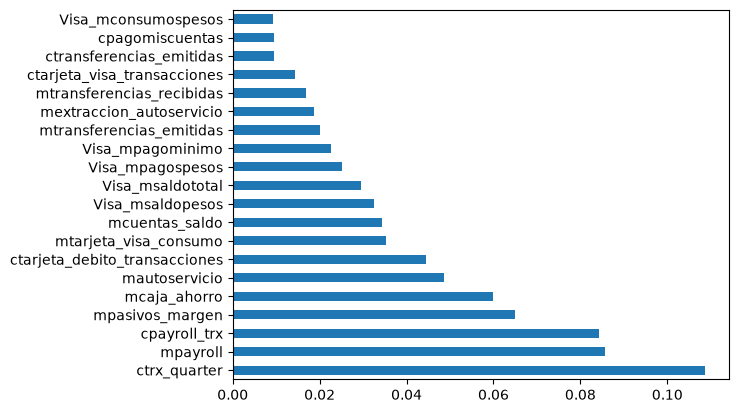

In [19]:
%matplotlib inline
feat_importances = pd.Series(rf.feature_importances_, index=feats)

# gráfico de barras horizontales
feat_importances.nlargest(20).plot(kind="barh")


## Analizando grupos asignados

In [34]:
# df.head()
# df.loc[df.grupo== 1, "clase_ternaria" ].value_counts()
# meses_total = sorted(df[MES_COL].unique().tolist())
# meses = meses_total[:-1]  # el ultimo mes no tiene BAJA+2 con historia
# feats = columnas_features(df)
# por_grupo 
df.loc[df[GRUPO_COL] == 1, "clase_ternaria"].value_counts()

clase_ternaria
CONTINUA    6148
BAJA+2      4067
BAJA+1      4067
Name: count, dtype: Int64

## 8. Prototipo: señal de alerta temprana para cluster 5

Reutiliza `df`, `labels`, `attrs_def` ya calculados arriba (no reentrena nada). Realinea el tiempo por "meses antes de la baja" en vez de mes calendario, y agrega una línea de referencia con el promedio de los clientes fieles.

In [ ]:
CLUSTER_ID = 5
OUT_ALERTA = OUT_PATH.parent / f"cluster{CLUSTER_ID}_alerta_temprana.pdf"

atributos_c = attrs_def.loc[attrs_def[CLUSTER_COL] == CLUSTER_ID, "atributo"].tolist()
log(f"cluster {CLUSTER_ID}: atributos evaluados -> {atributos_c}")

# periodo en meses consecutivos (evita restar foto_mes crudo si algun dia cruza de anio)
df["periodo0"] = (df[MES_COL] // 100) * 12 + (df[MES_COL] % 100)

# "T0" de cada cliente = el ultimo mes en que aparece en el dataset (justo antes de esfumarse)
ultimo_periodo = df.groupby(ID_COL)["periodo0"].transform("max")
df["meses_antes_baja"] = ultimo_periodo - df["periodo0"]

ids_c = labels[labels == CLUSTER_ID].index
d_c = df[df[ID_COL].isin(ids_c)]
fieles_baseline = df.loc[df[GRUPO_COL] == 0, atributos_c].mean()

def resumen_evento(d: pd.DataFrame, atributos: list[str], campo_tiempo: str) -> pd.DataFrame:
    g = d.groupby(campo_tiempo)[atributos]
    n = g.count()
    centro, sd = g.mean(), g.std()
    ancho = 1.96 * sd / np.sqrt(n)
    lo, hi = centro - ancho, centro + ancho
    lo = lo.clip(lower=d[atributos].min(), axis=1)
    hi = hi.clip(upper=d[atributos].max(), axis=1)
    return pd.concat({"centro": centro, "lo": lo, "hi": hi, "n": n}, axis=1)

eventos = sorted(d_c["meses_antes_baja"].unique())
tend_c = resumen_evento(d_c, atributos_c, "meses_antes_baja")
color_c = COLORES_CLUSTER[CLUSTER_ID - 1]

with PdfPages(OUT_ALERTA) as pdf:
    fig = plt.figure(figsize=(11.69, 8.27))
    texto = [
        f"Cluster {CLUSTER_ID}: {len(ids_c):,} clientes BAJA+2.",
        f"Atributos definitorios evaluados: {', '.join(atributos_c)}.",
        "",
        "Como leer cada pagina:",
        "  - Eje X = meses antes de desaparecer del dataset (0 = ultimo mes presente; a la izquierda, mas lejos en el tiempo).",
        f"  - Linea de color = media de cluster_{CLUSTER_ID} en ese punto del ciclo de vida; banda = IC 95%.",
        "  - Linea punteada gris = promedio de un cliente fiel (referencia de comportamiento normal).",
        "  - n al pie = cantidad de clientes del cluster con datos en ese punto (ojo con n chico).",
        "  - Si la linea de color se despega de la gris recien cerca del 0, es una señal tardia (poco margen de reaccion).",
        "  - Si se despega varios meses antes del 0, ahi hay una ventana real para actuar.",
    ]
    fig.text(0.06, 0.92, f"Cluster {CLUSTER_ID} - señal de alerta por meses antes de la baja",
             fontsize=18, color=INK, weight="bold", va="top")
    fig.text(0.06, 0.84, "\n".join(texto), fontsize=11, color=INK_2, va="top", linespacing=1.6)
    pdf.savefig(fig)
    plt.close(fig)

    for attr in atributos_c:
        fig = plt.figure(figsize=(11.69, 8.27))
        ax = fig.add_axes([0.09, 0.30, 0.87, 0.54])
        x = eventos
        centro = tend_c["centro"][attr].reindex(x).values
        lo, hi = tend_c["lo"][attr].reindex(x).values, tend_c["hi"][attr].reindex(x).values
        ax.fill_between(x, lo, hi, color=color_c, alpha=0.15, linewidth=0)
        ax.plot(x, centro, color=color_c, linewidth=2.2, marker="o", markersize=6, label=f"cluster_{CLUSTER_ID}")
        ax.axhline(fieles_baseline[attr], color="gray", linestyle="--", linewidth=1.5, label="fiel (referencia)")
        ax.invert_xaxis()  # 0 (a punto de irse) queda a la derecha
        _estilo(ax)
        ax.legend(frameon=False, fontsize=9, loc="best")
        ax.set_xlabel("meses antes de la baja", color=INK_2)
        ax.set_ylabel(attr, color=INK_2)
        fig.text(0.09, 0.945, attr, fontsize=20, color=INK, weight="bold")

        n_tab = tend_c["n"][attr].reindex(x).fillna(0).astype(int)
        ax_t = fig.add_axes([0.09, 0.06, 0.87, 0.14])
        ax_t.axis("off")
        tabla = ax_t.table(cellText=[n_tab.values], rowLabels=[f"n cluster_{CLUSTER_ID}"],
                           colLabels=[str(m) for m in x], loc="center", cellLoc="center")
        tabla.auto_set_font_size(False)
        tabla.set_fontsize(8.5)
        tabla.scale(1, 1.15)
        for (r, _c), cell in tabla.get_celld().items():
            cell.set_edgecolor(GRID)
            cell.get_text().set_color(INK_2 if r == 0 else INK)
        pdf.savefig(fig)
        plt.close(fig)

log(f"listo -> {OUT_ALERTA}")

[1450.7s] cluster 5: atributos evaluados -> ['mprestamos_personales', 'cprestamos_personales', 'cdescubierto_preacordado']
[1451.3s] listo -> cluster5_alerta_temprana.pdf
